In [ ]:
##Student Exam Scores Analysis: [Moderate] 
##o Dataset: UC "Students Performance in Exams" dataset. 
##o Tasks: Analyze score distributions and compare performance by gender, parental education, etc. 
##o Moderate Task: Test the hypothesis: "Does the 'test preparation course' lead to a 
##statistically significant difference in 'math score'?" (Use a T-test). 
##o Visuals: Histograms, box plots, and a seaborn pairplot of all three scores, colored by 
##test preparation course

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy as stats
from scipy.stats import ttest_ind

In [4]:
df = pd.read_csv("data analysis /students_final.csv", sep = ';')
df.head() ## to see the first 5 rows of the data 

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,Dalc,Walc,health,absences,G1_mat,G2_mat,G3_mat,G1_por,G2_por,G3_por
0,GP,F,15,R,GT3,T,1,1,at_home,other,...,1,1,1,2,7,10,10,13,13,13
1,GP,F,15,R,GT3,T,1,1,other,other,...,2,4,5,2,8,6,5,13,11,11
2,GP,F,15,R,GT3,T,2,2,at_home,other,...,1,1,2,8,14,13,13,14,13,12
3,GP,F,15,R,GT3,T,2,4,services,health,...,1,1,5,2,10,9,8,10,11,10
4,GP,F,15,R,GT3,T,3,3,services,services,...,2,3,3,8,10,10,10,13,13,13


In [5]:
df.tail() ## to the the last 5 rows of the data and see how many oserved IDs there are
## 381 

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,Dalc,Walc,health,absences,G1_mat,G2_mat,G3_mat,G1_por,G2_por,G3_por
377,MS,M,18,U,LE3,T,1,3,at_home,services,...,2,3,3,7,8,7,8,9,10,9
378,MS,M,18,U,LE3,T,4,4,teacher,services,...,2,2,5,0,13,13,13,15,16,16
379,MS,M,19,R,GT3,T,1,1,other,other,...,3,3,5,4,8,8,8,8,9,10
380,MS,M,19,R,GT3,T,1,1,other,services,...,3,3,2,8,8,7,8,10,9,11
381,MS,M,19,R,GT3,T,1,1,other,services,...,1,3,5,0,6,5,0,5,8,0


In [6]:
df.describe() ## i can see the maim measures of the variables on the dataset 

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1_mat,G2_mat,G3_mat,G1_por,G2_por,G3_por
count,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000,382.000000
mean,16.586387,2.806283,2.565445,1.442408,2.034031,0.290576,3.939791,3.222513,3.112565,1.473822,2.280105,3.578534,5.319372,10.861257,10.712042,10.387435,12.112565,12.238220,12.515707
std,1.173470,1.086381,1.096240,0.695378,0.845798,0.729481,0.921620,0.988233,1.131927,0.886229,1.282866,1.400360,7.625251,3.349167,3.832560,4.687242,2.556531,2.468341,2.945438
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000,0.000000,5.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,8.250000,8.000000,10.000000,11.000000,11.000000
50%,17.000000,3.000000,3.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,3.000000,10.500000,11.000000,11.000000,12.000000,12.000000,13.000000
75%,17.000000,4.000000,4.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000,14.000000,14.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000,19.000000,19.000000,19.000000


In [7]:
## understanding the data 
## load the columns
print("let's see what columns the df has")
print("=" * 140)
print(df.columns.tolist())

let's see what columns the df has
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'nursery', 'internet', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'higher', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1_mat', 'G2_mat', 'G3_mat', 'G1_por', 'G2_por', 'G3_por']


In [8]:
## identifying the test preparation column
test_prep = "paid"
print(f"using '{test_prep}' column for the test preparation analysis")

using 'paid' column for the test preparation analysis


TASK 1.1 - SCORE DISTRIBUTIONS


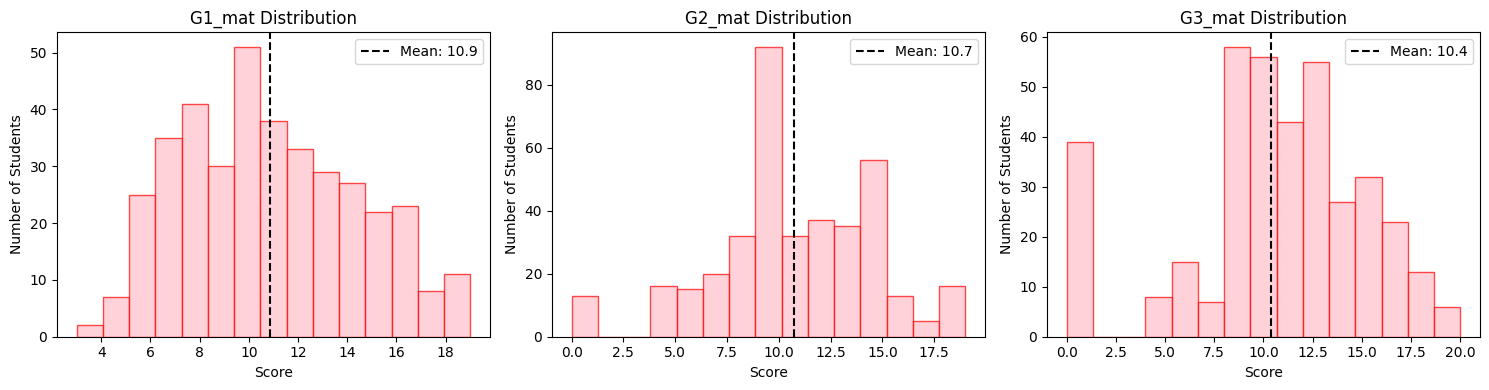

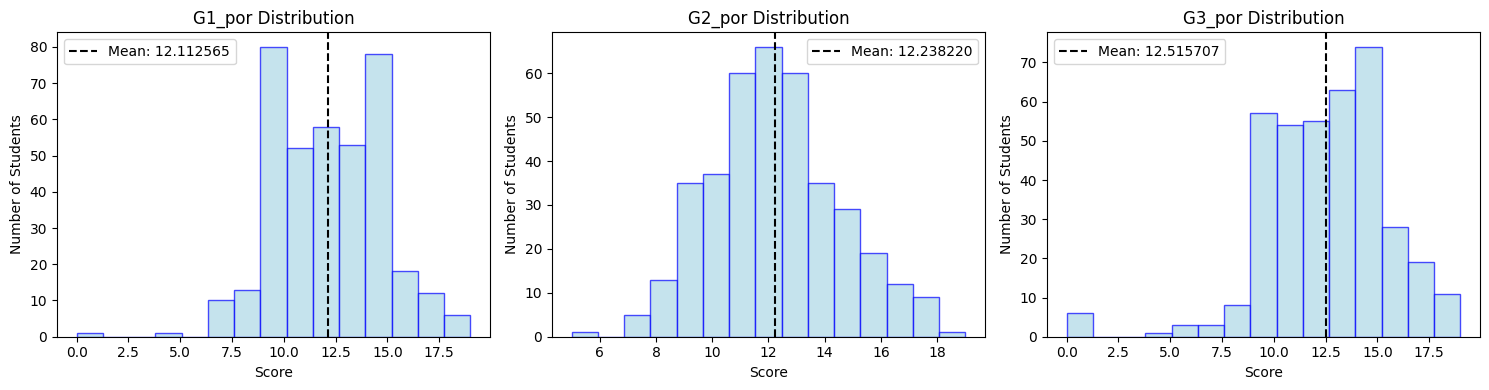

In [15]:
## TASK 1 -  Analyze score distributions and compare performance by gender, parental education, schoolsup and famsup
print("TASK 1.1 - SCORE DISTRIBUTIONS")
print("=" * 50)

## MATH SCORES 
plt.figure(figsize=(15, 4))
math_scores = ["G1_mat",	"G2_mat",	"G3_mat"]
for i, score in enumerate(math_scores):
    plt.subplot(1, 3, i+1)
    plt.hist(df[score], bins=15, color="pink", edgecolor="red", alpha=0.7)
    plt.axvline(df[score].mean(), color= "black", linestyle='--', label=f'Mean: {df[score].mean():.1f}')
    plt.title(f'{score} Distribution')
    plt.xlabel("Score")
    plt.ylabel("Number of Students")
    plt.legend()

plt.tight_layout()
plt.show()

## PORTUGUESE SCORES 
plt.figure(figsize=(15, 4))
por_scores = ["G1_por", "G2_por", "G3_por"]
for i, score in enumerate(por_scores): 
    plt.subplot(1, 3, i+1)
    plt.hist(df[score], bins = 15, color = "lightblue", edgecolor = "blue", alpha = 0.7)
    plt.axvline(df[score].mean(), color = "black", linestyle = "--", label = f"Mean: {df[score].mean():1f}")
    plt.title(f'{score} Distribution')
    plt.xlabel("Score")
    plt.ylabel("Number of Students")
    plt.legend()

plt.tight_layout()
plt.show()

TASK 1.2 = COMPARE PERFORMANCE BY GENDER, PARENTAL EDUCATION, FAMILY AND SCHOOL SUPPORT


([0, 1, 2, 3],
 [Text(0, 0, 'Low Edu'),
  Text(1, 0, 'Moderate Edu'),
  Text(2, 0, 'One High Edu'),
  Text(3, 0, 'Both High Edu')])

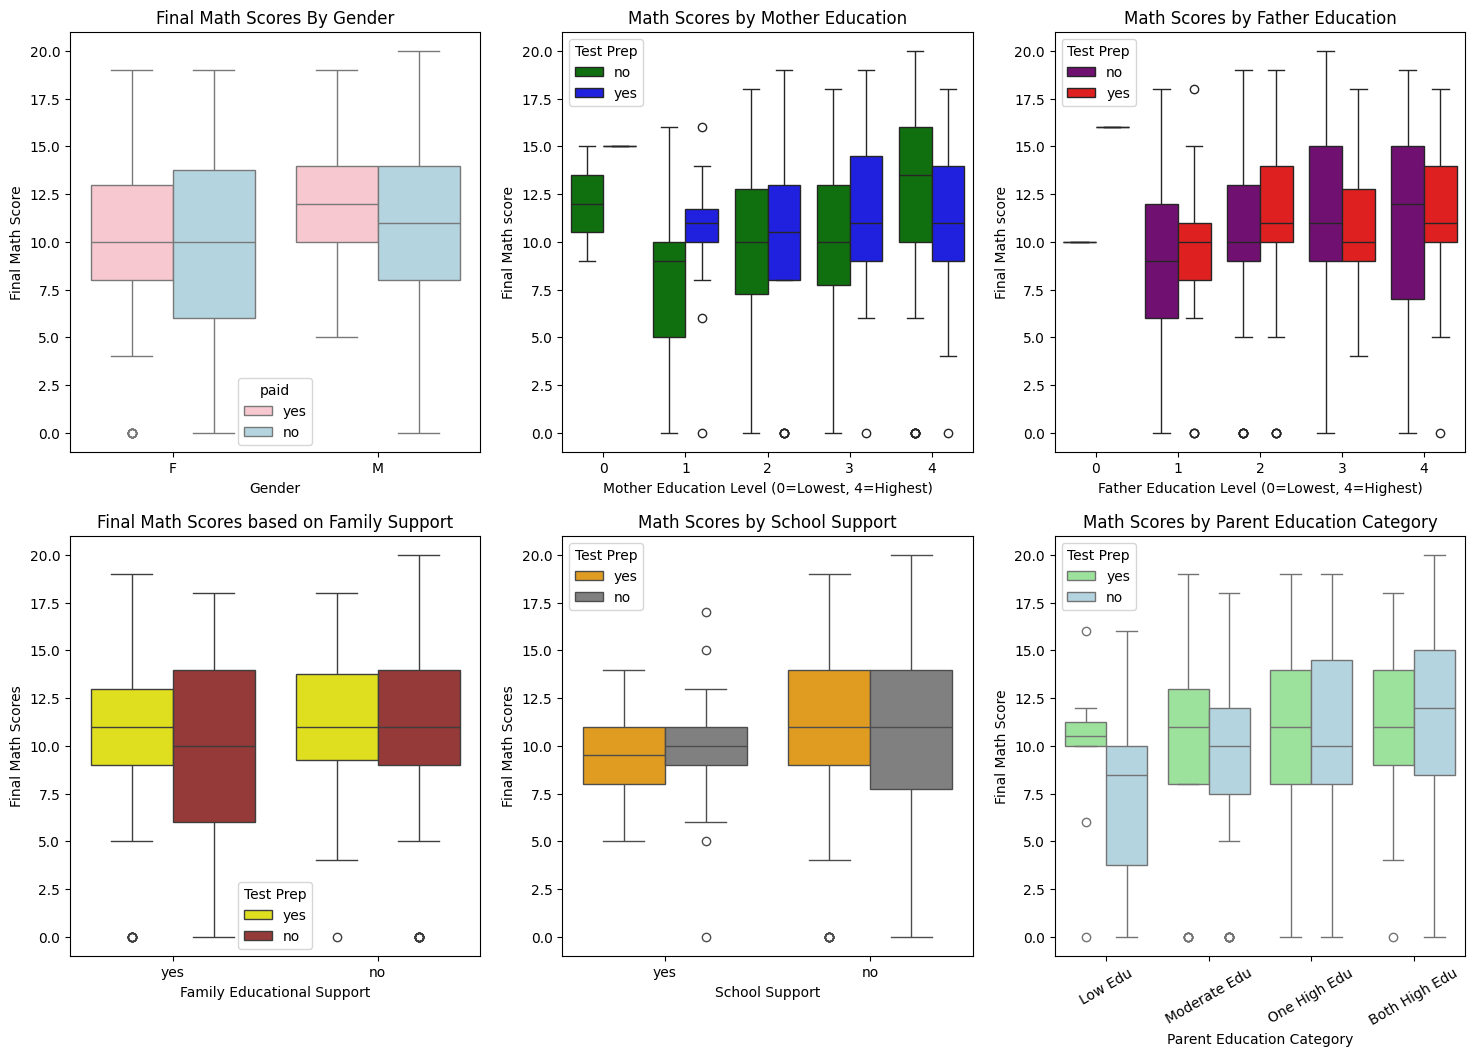

In [36]:
## The main focus will be on comparing the perormance of students in math exam since the further test hypothesis focuses
## on math scores rather than portuguese. The distrubuts of the latter have been shown using histograms in task 1. 
print("TASK 1.2 = COMPARE PERFORMANCE BY GENDER, PARENTAL EDUCATION, FAMILY AND SCHOOL SUPPORT")
print("=" * 100)
## create a canvas 2*2 for the comparison 
plt.figure(figsize = (18, 12))

## 1. GENDER COMPARISON 
plt.subplot(2,3,1)
sns.boxplot(data = df, x = 'sex', y = 'G3_mat', hue = test_prep, palette = ['pink', 'lightblue'])
plt.title("Final Math Scores By Gender")
plt.xlabel("Gender")
plt.ylabel("Final Math Score")

## 2. MOTHER'S AND FATHER'S EDUCATION COMPARISON 
plt.subplot(2,3,2)
sns.boxplot(data = df, x = 'Medu', y = 'G3_mat', hue = test_prep, palette = ['green', 'blue'])
plt.title("Math Scores by Mother Education")
plt.xlabel("Mother Education Level (0=Lowest, 4=Highest)")
plt.ylabel("Final Math score")
plt.legend(title="Test Prep")

plt.subplot(2,3,3)
sns.boxplot(data = df, x = 'Fedu', y = 'G3_mat', hue = test_prep, palette = {'yes': 'red', 'no':'purple'})
plt.title("Math Scores by Father Education")
plt.xlabel("Father Education Level (0=Lowest, 4=Highest)")
plt.ylabel("Final Math score")
plt.legend(title="Test Prep")

## 3. COMPARISON BY FAMILY SUPPORT 
plt.subplot(2,3,4)
sns.boxplot (data = df, x = "famsup", y = "G3_mat", hue = test_prep, palette = ['yellow', 'brown'])
plt.title("Final Math Scores based on Family Support")
plt.xlabel("Family Educational Support")
plt.ylabel("Final Math Scores")
plt.legend(title='Test Prep')

## 4. COMPARISON BY SCHOOL SUPPORT 
plt.subplot(2,3,5)
sns.boxplot(data = df, x = "schoolsup", y = "G3_mat", hue = test_prep, palette = {'yes':'orange', 'no':'grey'})
plt.title("Math Scores by School Support")
plt.xlabel('School Support')
plt.ylabel('Final Math Scores')
plt.legend(title = 'Test Prep')

## 5. COMBINED COMPARISON BY PARENT'S EDUCATION 
plt.subplot(2,3,6)
## create a column with combined mother's and father's education levels 
#  create parent education categories
def categorize_parent_edu(row):
    if row['Medu'] >= 3 and row['Fedu'] >= 3:
        return 'Both High Edu'
    elif row['Medu'] >= 3 or row['Fedu'] >= 3:
        return 'One High Edu'
    elif row['Medu'] >= 2 or row['Fedu'] >= 2:
        return 'Moderate Edu'
    else:
        return 'Low Edu'

df['parent_edu_category'] = df.apply(categorize_parent_edu, axis=1)

# order the categories logically
edu_order = ['Low Edu', 'Moderate Edu', 'One High Edu', 'Both High Edu']

sns.boxplot(data=df, x='parent_edu_category', y='G3_mat', hue=test_prep,
            palette={'yes': 'lightgreen', 'no': 'lightblue'}, order=edu_order)
plt.title('Math Scores by Parent Education Category')
plt.xlabel('Parent Education Category')
plt.ylabel('Final Math Score')
plt.legend(title='Test Prep')
plt.xticks(rotation=30)

In [129]:
## calculate the aevrages for each group
print ('Averages of Math Scores of each group')
print ('='*50)

##BY GENDER 
print ('BY GENDER')
print('='*50)
print(f"Male: {df[df['sex'] == 'M']['G3_mat'].mean():.2f}")
print(f"Female: {df[df['sex'] == 'F']['G3_mat'].mean():.2f}")

## BY PARENT EDUCATION 
## Mother's education 
print('MOTHER EDUCATION')
print('='*50)
medu_mean = df.groupby('Medu')['G3_mat'].mean()
for level, avg in medu_mean.items():
    print(f"Level {level}: {avg:.2f}")
## Father Educaation 
print('FATHER EDUCATION')
print('='*50)
fedu_mean = df.groupby('Fedu')['G3_mat'].mean()
for level, avg in fedu_mean.items():
    print(f"Level {level}: {avg:.2f}")
## combined parent education 
print('COMBINED PARENT EDUCATION')
print('='*50)
comb_par_educ_mean = df.groupby('parent_edu_category')['G3_mat'].mean().sort_values(ascending = False)
for category, avg in comb_par_educ_mean.items():
    print(f"  {category}: {avg:.2f}")

## SUPPORT 
print('SUPPORT BY SCHOOL AND FAMILY')
print('=' * 50)
famsup_mean = df.groupby('famsup')['G3_mat'].mean()
schoolsup_mean = df.groupby('schoolsup')['G3_mat'].mean()
print(f"  Family Support: yes={df[df['famsup'] == 'yes']['G3_mat'].mean():.2f}, no={df[df['famsup'] == 'no']['G3_mat'].mean():.2f}")
print(f"  School Support: yes={df[df['schoolsup'] == 'yes']['G3_mat'].mean():.2f}, no={df[df['schoolsup'] == 'no']['G3_mat'].mean():.2f}")

## COMBINED PARENTAL EDUCATION AND TEST PREPARATION - checking if low education families have higher results with test preparation 
## than high education families 
print("EFFECTS OF TEST PREPARATION ON DIFFERNT CATEGORIES OF PARENT EDUCATION FAMILIES")
print('='*100)
parent_prep_mean = df.groupby(['parent_edu_category', test_prep])['G3_mat'].mean()
for (category, prep), avg in parent_prep_mean.items():
    prep_status = 'WITH' if prep == 'yes' else 'WITHOUT'
    print(f"{category}{prep_status} test prep: {avg:.2f}")
    
print('FINDING')
print('='*50)
print(f" Gender: {'Male' if df[df['sex'] == 'M']['G3_mat'].mean() > df[df['sex'] == 'F']['G3_mat'].mean() else 'Female'} students score higher")
print(f"Family Support: {'helps' if famsup_mean['yes'] > famsup_mean['no'] else 'No clear effect'} ({famsup_mean['yes']:.1f} vs {famsup_mean['no']:.1f})")
## students without family support score higher than wwith family supports. 
##this migh suggest that students without family become more indeendent and care more responsbility
print(f"School Support: {'helps' if schoolsup_mean['yes'] > schoolsup_mean['no'] else 'No clear effect'} ({schoolsup_mean['yes']:.1f} vs {schoolsup_mean['no']:.1f})")
## school support also does not show any effectivness. it might suggest that it needs improvement

Averages of Math Scores of each group
BY GENDER
Male: 10.98
Female: 9.84
MOTHER EDUCATION
Level 0: 13.00
Level 1: 8.57
Level 2: 9.62
Level 3: 10.37
Level 4: 11.59
FATHER EDUCATION
Level 0: 13.00
Level 1: 8.70
Level 2: 10.53
Level 3: 10.73
Level 4: 11.15
COMBINED PARENT EDUCATION
  Both High Edu: 11.02
  One High Edu: 11.01
  Moderate Edu: 9.52
  Low Edu: 8.08
SUPPORT BY SCHOOL AND FAMILY
  Family Support: yes=10.21, no=10.69
  School Support: yes=9.49, no=10.53
EFFECTS OF TEST PREPARATION ON DIFFERNT CATEGORIES OF PARENT EDUCATION FAMILIES
Both High EduWITHOUT test prep: 10.77
Both High EduWITH test prep: 11.27
Low EduWITHOUT test prep: 7.17
Low EduWITH test prep: 9.92
Moderate EduWITHOUT test prep: 9.12
Moderate EduWITH test prep: 10.05
One High EduWITHOUT test prep: 10.84
One High EduWITH test prep: 11.20
FINDING
 Gender: Male students score higher
Family Support: No clear effect (10.2 vs 10.7)
School Support: No clear effect (9.5 vs 10.5)


In [82]:
## TASK 3 - T-TEST 
print("MODERATE TASK - Test the hypothesis: Does the test preparation course lead to a statistically significant difference in math score?")
print('='* 140)
math_with_prep = df[df[test_prep] == 'yes']['G3_mat']
math_without_prep = df[df[test_prep] == 'no']['G3_mat']
print(f"Students WITH test preparation: {len(math_with_prep)}")
print(f"Students WITHOUT test preparation: {len(math_without_prep)}")
print(f"Average score of students WITH test preparaton: {math_with_prep.mean():.2f}")
print(f"Average score of students WITHOUT test preparaton: {math_without_prep.mean():.2f}")

## t - test 
t_stat, p_value = ttest_ind(math_with_prep, math_without_prep)
print('='*50)
print("T-TEST RESULTS")
print(f"t-statistic = {t_stat:.4f}")
print(f"p_value = {p_value:.4f}")
print('='*50)
print('T-TEST CONCLUSION AND INTERPRETATION')
if p_value < 0.05: 
    print("REJECT THE NULL NYPOTHESIS")
    difference = math_with_prep.mean() - math_without_prep.mean()
    print("Test preparation courses LEADS to statistically significant results in the final math score results")
    print(f" with difference = {difference} points")
else: 
    print("FAIL TO REJECT THE NULL HYPOTHESIS")
    print("There is not enough evidence to prove that test preparation courses")
    print("lead to significant difference in the final math score reults")  

MODERATE TASK - Test the hypothesis: Does the test preparation course lead to a statistically significant difference in math score?
Students WITH test preparation: 177
Students WITHOUT test preparation: 205
Average score of students WITH test preparaton: 10.89
Average score of students WITHOUT test preparaton: 9.95
T-TEST RESULTS
t-statistic = 1.9649
p_value = 0.0502
T-TEST CONCLUSION AND INTERPRETATION
FAIL TO REJECT THE NULL HYPOTHESIS
There is not enough evidence to prove that test preparation courses
lead to significant difference in the final math score reults


VISUALS: boxplot and pairplot


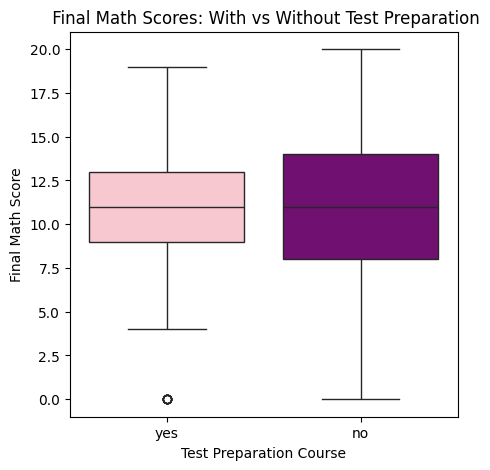

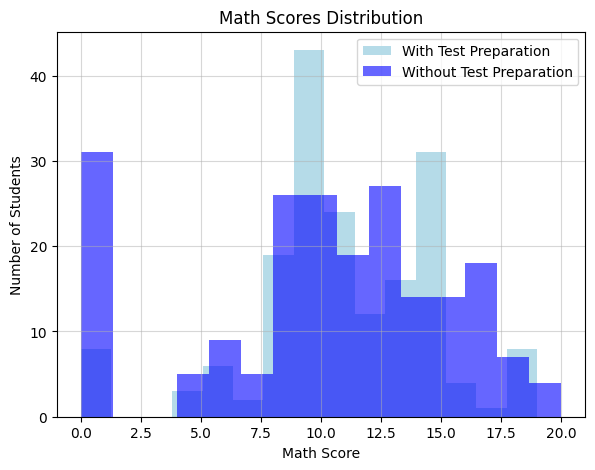

ALL THREE MATH SCORES


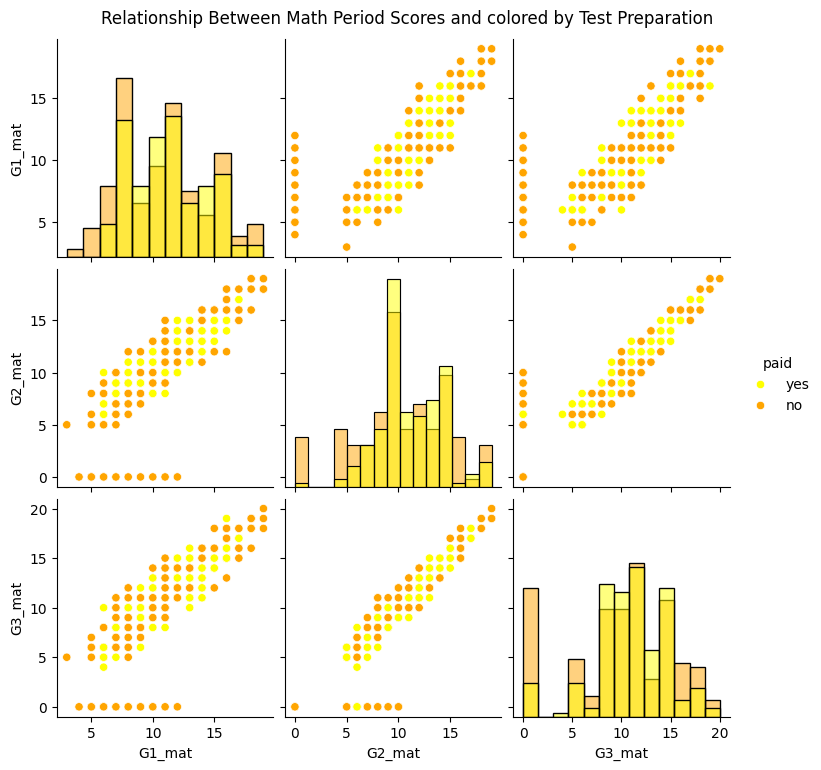

In [119]:
## VISUALS -  Histograms, box plots, and a seaborn pairplot of all three scores, colored by 
##test preparation course
print("VISUALS: boxplot and pairplot")
print('='*50)
## boxplot for the test peparation and math scores 
plt.figure(figsize = (5,5))
sns.boxplot(data = df, x = test_prep, y = 'G3_mat', hue = test_prep, palette = ['pink', 'purple'])
plt.title(" Final Math Scores: With vs Without Test Preparation")
plt.xlabel("Test Preparation Course")
plt.ylabel("Final Math Score")
plt.show()
## the boxplot shows that students without test preparation scored higher than students with test preparation

## histogram comparing test preparation
plt.figure(figsize = (15,5))
plt.subplot(1,2,1)
plt.hist(math_with_prep, bins = 15, alpha = 0.9, color = 'lightblue', label = "With Test Preparation")
plt.hist(math_without_prep, bins = 15, alpha = 0.6, color = 'blue', label = "Without Test Preparation")
plt.title("Math Scores Distribution")
plt.xlabel("Math Score")
plt.ylabel("Number of Students")
plt.legend()
plt.grid(alpha=0.5)
plt.show()
## there is a significant overlap between groups implying what t-test proved - test preparation is not the main factor affecting score resluts
## most students score in the rangw from 8-15 points
## with test preparation more stidents have high scores and it is less divers while students without test preparation have more lower scores

print("ALL THREE MATH SCORES")
sns.pairplot(df, vars = ['G1_mat', 'G2_mat', 'G3_mat'], 
             hue=test_prep,
             palette={'yes': 'yellow', 'no': 'orange'},
             diag_kind='hist')
plt.suptitle("Relationship Between Math Period Scores and colored by Test Preparation", y=1.02)
plt.show()